# TP N°3 : Modélisation (Machine learning)

## Exercice 1

In [1]:
import re
import warnings
import joblib
import warnings
import nltk
import numpy as np
import pandas as pd
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

warnings.filterwarnings("ignore")
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)

data = [
    ("Hey, are we still meeting for lunch at 1pm today?", "ham"),
    ("WINNER!! You have been selected to receive a £500 cash prize. Call 09061234567 now to claim!", "spam"),
    ("Can you pick up some milk on your way home?", "ham"),
    ("URGENT! Your mobile number has won a FREE holiday. Text CLAIM to 81010 to collect.", "spam"),
    ("I'll be late, the bus is stuck in traffic. Start without me.", "ham"),
    ("Congratulations! You've been chosen for a free iPhone. Click www.free-prize-now.com to claim.", "spam"),
    ("Thanks for helping me with my homework yesterday, I really appreciate it.", "ham"),
    ("FreeMsg: Get 6 months of unlimited calls for FREE! Reply YES to 87121. T&Cs apply.", "spam"),
    ("Don't forget mom's birthday is on Sunday, I'll bring the cake.", "ham"),
    ("Your bank account has been suspended. Verify your details now at www.secure-bank-login.net", "spam"),
    ("Did you finish the report? The boss is asking about it.", "ham"),
    ("You have 1 new voicemail. Call 08712400602 to listen. Cost 50p per min.", "spam"),
    ("Good night, see you tomorrow morning at the gym.", "ham"),
    ("Last chance! Win £1000 cash every week. Text WIN to 80082 now. 16+ only.", "spam"),
    ("Happy birthday! Hope you have an amazing day with your family.", "ham"),
]
df = pd.DataFrame(data, columns=["text", "label"])

In [2]:
stop_words = set(stopwords.words("english")) - {"not", "no"}

def fix_contractions(text):
    text = text.replace("’", "'")
    text = text.replace("won't", "will not").replace("can't", "can not")
    text = re.sub(r"n't", " not", text)
    text = re.sub(r"'re", " are", text)
    text = re.sub(r"'ve", " have", text)
    text = re.sub(r"'ll", " will", text)
    text = re.sub(r"'d", " would", text)
    text = re.sub(r"'m", " am", text)
    text = re.sub(r"'s", " is", text)
    return text

def preprocess_text(text):
    text = text.lower()
    text = fix_contractions(text)
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in stop_words]
    tokens = [t for t in tokens if t.isalpha()]
    return " ".join(tokens)

df["clean_text"] = df["text"].apply(preprocess_text)
df

,text,label,clean_text
0,"Hey, are we still meeting for lunch at 1pm today?",ham,hey still meeting lunch today
1,WINNER!! You have been selected to receive a £...,spam,winner selected receive cash prize call claim
2,Can you pick up some milk on your way home?,ham,pick milk way home
3,URGENT! Your mobile number has won a FREE holi...,spam,urgent mobile number free holiday text claim c...
4,"I'll be late, the bus is stuck in traffic. Sta...",ham,late bus stuck traffic start without
5,Congratulations! You've been chosen for a free...,spam,congratulations chosen free iphone click claim
6,Thanks for helping me with my homework yesterd...,ham,thanks helping homework yesterday really appre...
7,FreeMsg: Get 6 months of unlimited calls for F...,spam,freemsg get months unlimited calls free reply ...
8,"Don't forget mom's birthday is on Sunday, I'll...",ham,not forget mom birthday sunday bring cake
9,Your bank account has been suspended. Verify y...,spam,bank account suspended verify details


In [3]:
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(df["clean_text"])
y = df["label"].map({"ham": 0, "spam": 1})
print(X.shape)

(15, 86)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

acc_l, prec_l, rec_l, f1_l = [], [], [], []
best_f1 = -1
best_model = None

for fold, (tr, va) in enumerate(skf.split(X_train, y_train), 1):
    X_tr, X_va = X_train[tr], X_train[va]
    y_tr, y_va = y_train.iloc[tr], y_train.iloc[va]

    rf = RandomForestClassifier(random_state=42)
    rf.fit(X_tr, y_tr)
    pred = rf.predict(X_va)

    acc = accuracy_score(y_va, pred)
    prec = precision_score(y_va, pred, zero_division=0)
    rec = recall_score(y_va, pred, zero_division=0)
    f1 = f1_score(y_va, pred, zero_division=0)
    acc_l.append(acc); prec_l.append(prec); rec_l.append(rec); f1_l.append(f1)
    print(fold, round(acc, 3), round(prec, 3), round(rec, 3), round(f1, 3))

    if f1 > best_f1:
        best_f1 = f1
        best_model = rf

print("accuracy :", np.mean(acc_l))
print("precision:", np.mean(prec_l))
print("recall   :", np.mean(rec_l))
print("f1-score :", np.mean(f1_l))

1 0.667 0.0 0.0 0.0


2 0.333 0.0 0.0 0.0


3 0.5 0.0 0.0 0.0


4 1.0 1.0 1.0 1.0


5 1.0 1.0 1.0 1.0
accuracy : 0.7
precision: 0.4
recall   : 0.4
f1-score : 0.4


In [5]:
pred = best_model.predict(X_test)
print("accuracy :", accuracy_score(y_test, pred))
print("precision:", precision_score(y_test, pred, zero_division=0))
print("recall   :", recall_score(y_test, pred, zero_division=0))
print("f1-score :", f1_score(y_test, pred, zero_division=0))
print(classification_report(y_test, pred, zero_division=0))

accuracy : 0.6666666666666666
precision: 0.0
recall   : 0.0
f1-score : 0.0
              precision    recall  f1-score   support

           0       0.67      1.00      0.80         2
           1       0.00      0.00      0.00         1

    accuracy                           0.67         3
   macro avg       0.33      0.50      0.40         3
weighted avg       0.44      0.67      0.53         3



In [6]:
_ = joblib.dump(best_model, "rf_binary.pkl")
_ = joblib.dump(vectorizer, "bow_vectorizer.pkl")

In [7]:
from sklearn.model_selection import cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

models = {
    "LogReg": LogisticRegression(max_iter=1000),
    "NaiveBayes": MultinomialNB(),
    "LinearSVM": LinearSVC(),
    "KNN": KNeighborsClassifier(n_neighbors=3),
    "DecisionTree": DecisionTreeClassifier(random_state=42),
    "RandomForest": RandomForestClassifier(random_state=42),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = {}
for name, m in models.items():
    r = cross_validate(m, X, y, cv=cv, scoring=["accuracy", "precision", "recall", "f1"])
    rows[name] = {k: r["test_" + k].mean() for k in ["accuracy", "precision", "recall", "f1"]}
res1 = pd.DataFrame(rows).T.sort_values("f1", ascending=False).round(3)
res1

,accuracy,precision,recall,f1
NaiveBayes,0.867,0.6,0.6,0.600
LinearSVM,0.733,0.6,0.4,0.467
DecisionTree,0.667,0.4,0.3,0.333
LogReg,0.600,0.2,0.2,0.200
RandomForest,0.600,0.2,0.2,0.200
KNN,0.533,0.0,0.0,0.000


## Exercice 2

In [8]:
import joblib
import warnings
import re
import warnings
import nltk
import pandas as pd
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore")
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)

tech = [
    "The new smartphone has a faster processor and a better camera.",
    "I am learning Python to build machine learning models.",
    "The software update fixes several security bugs in the operating system.",
    "Cloud computing lets companies store data on remote servers.",
    "This laptop has 16 GB of RAM and a fast SSD.",
    "Developers are using artificial intelligence to generate code.",
    "My wifi router needs a firmware update to improve the network speed.",
    "The startup released an app that uses facial recognition.",
    "Software engineers write code and test the application on the server.",
    "The computer network needs a new router and faster internet.",
    "Data scientists train machine learning models on large datasets.",
    "This new app uses artificial intelligence and cloud technology.",
    "The hacker exploited a security bug in the software.",
    "I bought a new laptop with a powerful processor and a big screen.",
    "The database server stores user data in the cloud.",
    "Programmers debug the code before releasing the new software version.",
]
hobby = [
    "I love painting landscapes on weekends with watercolors.",
    "My favorite pastime is baking bread and trying new recipes.",
    "She spends her evenings knitting scarves for her friends.",
    "We went hiking in the mountains and took lots of photos.",
    "I've started collecting vintage stamps from around the world.",
    "Gardening relaxes me, especially growing tomatoes and herbs.",
    "He plays the guitar and writes songs in his free time.",
    "On Sundays I enjoy reading novels in the garden.",
    "I enjoy painting and drawing in my free time.",
    "My hobby is gardening, I grow flowers and vegetables.",
    "She loves cooking and baking cakes at home.",
    "On weekends we go hiking and camping in nature.",
    "He collects old coins and vintage records as a hobby.",
    "I like reading books and listening to music in the evening.",
    "Playing the piano and writing poems are my favorite hobbies.",
    "We spend our holidays fishing, sailing and taking photos.",
]
work = [
    "I have a meeting with my manager at ten to discuss the project deadline.",
    "Please send the quarterly report to the finance department by Friday.",
    "The company is hiring two new employees for the marketing team.",
    "My colleague is presenting the sales results to the clients today.",
    "I need to update my resume before the job interview next week.",
    "The office will be closed during the holidays, please plan your tasks.",
    "She got promoted to senior director after years at the firm.",
    "We must finish the budget proposal before the end of the month.",
    "The manager scheduled a meeting about the project budget.",
    "I sent the report to the client and updated the team.",
    "Our company is recruiting a new employee for the sales department.",
    "The deadline for the project is Friday, so the whole team is busy.",
    "My boss approved my vacation request and my new contract.",
    "She is preparing a presentation for the board of directors.",
    "The office staff attended a training about customer service.",
    "He has a job interview tomorrow for a position in finance.",
]
sport = [
    "The striker scored two goals in the final minutes of the match.",
    "She won the gold medal in the hundred meter sprint.",
    "Our basketball team trained hard before the championship game.",
    "The tennis player served an ace to win the tournament.",
    "He runs ten kilometers every morning to prepare for the marathon.",
    "The goalkeeper saved a penalty and the crowd cheered loudly.",
    "The cyclist took the lead on the final climb of the race.",
    "The coach changed the lineup before the second half of the game.",
    "The football team won the match with a late goal.",
    "The player scored and the coach praised the whole team.",
    "She trains every day to win the swimming championship.",
    "The runner broke the record in the marathon race.",
    "Our basketball team lost the game but played well.",
    "The tennis match lasted three hours and the champion won.",
    "Fans cheered for their team in the stadium during the final.",
    "The athlete won a medal at the Olympic games.",
]
texts = tech + hobby + work + sport
labels = ["tech"] * len(tech) + ["hobby"] * len(hobby) + ["work"] * len(work) + ["sport"] * len(sport)
df = pd.DataFrame({"text": texts, "label": labels})

In [9]:
stop_words = set(stopwords.words("english")) - {"not", "no"}

def fix_contractions(text):
    text = text.replace("’", "'")
    text = text.replace("won't", "will not").replace("can't", "can not")
    text = re.sub(r"n't", " not", text)
    text = re.sub(r"'re", " are", text)
    text = re.sub(r"'ve", " have", text)
    text = re.sub(r"'ll", " will", text)
    text = re.sub(r"'d", " would", text)
    text = re.sub(r"'m", " am", text)
    text = re.sub(r"'s", " is", text)
    return text

def preprocess_text(text):
    text = text.lower()
    text = fix_contractions(text)
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in stop_words]
    tokens = [t for t in tokens if t.isalpha()]
    return " ".join(tokens)

df["clean_text"] = df["text"].apply(preprocess_text)
df.head()

,text,label,clean_text
0,The new smartphone has a faster processor and ...,tech,new smartphone faster processor better camera
1,I am learning Python to build machine learning...,tech,learning python build machine learning models
2,The software update fixes several security bug...,tech,software update fixes several security bugs op...
3,Cloud computing lets companies store data on r...,tech,cloud computing lets companies store data remo...
4,This laptop has 16 GB of RAM and a fast SSD.,tech,laptop gb ram fast ssd


In [10]:
tfidf = TfidfVectorizer()
X = tfidf.fit_transform(df["clean_text"])

label_map = {"tech": 0, "hobby": 1, "work": 2, "sport": 3}
inv_map = {v: k for k, v in label_map.items()}
y = df["label"].map(label_map)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [11]:
rf = RandomForestClassifier(random_state=42)
params = {"n_estimators": [50, 100, 200], "max_depth": [5, 10, 15]}

search = RandomizedSearchCV(rf, params, n_iter=3, scoring="accuracy", cv=5, random_state=42)
search.fit(X_train, y_train)

print(search.best_params_)
print(search.best_score_)

{'n_estimators': 100, 'max_depth': 15}
0.5836363636363636


In [12]:
best = search.best_estimator_
pred = best.predict(X_test)

print("accuracy :", accuracy_score(y_test, pred))
print("precision:", precision_score(y_test, pred, average="weighted", zero_division=0))
print("recall   :", recall_score(y_test, pred, average="weighted", zero_division=0))
print("f1-score :", f1_score(y_test, pred, average="weighted", zero_division=0))
print(classification_report(y_test, pred, target_names=[inv_map[i] for i in range(4)], zero_division=0))
print(confusion_matrix(y_test, pred))

accuracy : 0.5384615384615384
precision: 0.7527472527472526
recall   : 0.5384615384615384
f1-score : 0.5087912087912089
              precision    recall  f1-score   support

        tech       1.00      0.33      0.50         3
       hobby       0.43      1.00      0.60         3
        work       1.00      0.25      0.40         4
       sport       0.50      0.67      0.57         3

    accuracy                           0.54        13
   macro avg       0.73      0.56      0.52        13
weighted avg       0.75      0.54      0.51        13

[[1 2 0 0]
 [0 3 0 0]
 [0 1 1 2]
 [0 1 0 2]]


In [13]:
_ = joblib.dump(best, "rf_multiclass.pkl")
_ = joblib.dump(tfidf, "tfidf_multiclass.pkl")

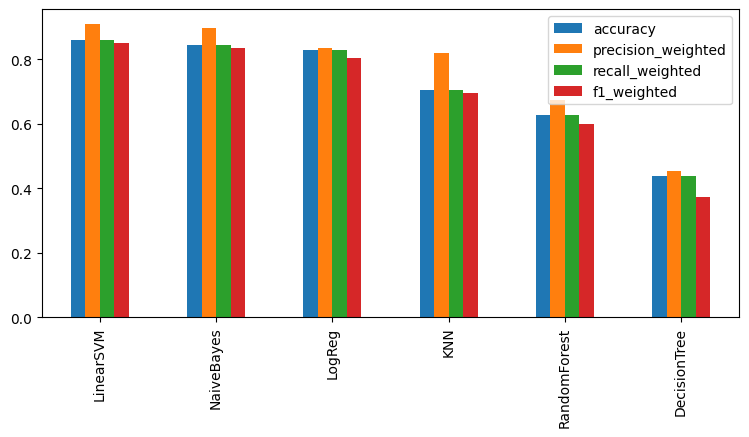

,accuracy,precision_weighted,recall_weighted,f1_weighted
LinearSVM,0.859,0.911,0.859,0.850
NaiveBayes,0.844,0.899,0.844,0.834
LogReg,0.828,0.834,0.828,0.806
KNN,0.705,0.821,0.705,0.696
RandomForest,0.627,0.673,0.627,0.599
DecisionTree,0.437,0.452,0.437,0.374


In [14]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

models = {
    "LogReg": LogisticRegression(max_iter=1000),
    "NaiveBayes": MultinomialNB(),
    "LinearSVM": LinearSVC(),
    "KNN": KNeighborsClassifier(n_neighbors=3),
    "DecisionTree": DecisionTreeClassifier(random_state=42),
    "RandomForest": RandomForestClassifier(random_state=42),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = {}
for name, m in models.items():
    r = cross_validate(m, X, y, cv=cv, scoring=["accuracy", "precision_weighted", "recall_weighted", "f1_weighted"])
    rows[name] = {k: r["test_" + k].mean() for k in ["accuracy", "precision_weighted", "recall_weighted", "f1_weighted"]}
res2 = pd.DataFrame(rows).T.sort_values("f1_weighted", ascending=False).round(3)
res2.plot(kind="bar", figsize=(9, 4))
plt.show()
res2

## Exercice 3

In [15]:
import re
import warnings
import joblib
import warnings
import nltk
import numpy as np
import pandas as pd
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, hamming_loss, classification_report

warnings.filterwarnings("ignore")
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)

data = [
    ("The government announced new funding for AI research in universities.", ["politics", "tech", "education"]),
    ("The football club signed a record sponsorship deal with a telecom company.", ["sport", "business"]),
    ("A new wearable device monitors heart rate and sleep quality.", ["tech", "health"]),
    ("The minister proposed a reform of the national school curriculum.", ["politics", "education"]),
    ("Startups are raising millions to develop mobile health applications.", ["business", "tech", "health"]),
    ("The marathon runner shared her nutrition plan to stay healthy.", ["sport", "health"]),
    ("Parliament debated the new tax on large technology companies.", ["politics", "business", "tech"]),
    ("Students learn coding and robotics in the new after-school program.", ["education", "tech"]),
    ("The stock market fell after the central bank raised interest rates.", ["business", "politics"]),
    ("Doctors recommend regular exercise to reduce the risk of heart disease.", ["health", "sport"]),
    ("The university opened a sports science department with modern labs.", ["education", "sport", "health"]),
    ("The president signed a law to protect personal data online.", ["politics", "tech"]),
    ("Online courses help employees improve their skills and advance their careers.", ["education", "business"]),
    ("The hospital uses machine learning to detect cancer in medical images.", ["health", "tech"]),
    ("The Olympic committee discussed the budget for the next games.", ["sport", "politics", "business"]),
    ("Vaccination campaigns were launched in schools across the country.", ["health", "education", "politics"]),
    ("The bank introduced a mobile app for instant payments.", ["business", "tech"]),
    ("The basketball star launched a clothing brand and a charity foundation.", ["sport", "business"]),
    ("Election candidates promised to lower unemployment and increase wages.", ["politics", "business"]),
    ("Researchers developed a low-cost sensor to monitor air pollution.", ["tech", "health"]),
    ("The coach teaches students how to prevent injuries during training.", ["sport", "education", "health"]),
    ("The software firm reported record profits this quarter.", ["business", "tech"]),
    ("Mental health support is now offered to all university students.", ["health", "education"]),
    ("The government invests in broadband to connect rural schools to the internet.", ["politics", "education", "tech"]),
    ("The football federation elected a new president after a heated vote.", ["sport", "politics"]),
    ("Pharmaceutical companies reported strong sales of the new diabetes drug.", ["business", "health"]),
    ("Teachers use tablets and educational apps in their classrooms.", ["education", "tech"]),
    ("The tennis tournament attracted sponsors and boosted the local economy.", ["sport", "business"]),
    ("A new law requires companies to offer wellness programs to employees.", ["politics", "business", "health"]),
    ("The e-sports league is growing fast and universities now offer scholarships.", ["sport", "tech", "education"]),
    ("The senator criticized the plan to cut public hospital funding.", ["politics", "health"]),
    ("Telemedicine platforms let patients consult doctors from home.", ["health", "tech"]),
    ("The retailer opened fifty new stores and hired thousands of workers.", ["business"]),
    ("The swimming team won the national title after a perfect season.", ["sport"]),
    ("The school organized a science fair about renewable energy and robotics.", ["education", "tech"]),
    ("Diplomats met to negotiate a new trade agreement between the two countries.", ["politics", "business"]),
    ("Yoga classes help reduce stress and improve concentration for students.", ["health", "education"]),
    ("The cybersecurity firm warned banks about a wave of phishing attacks.", ["tech", "business"]),
    ("The city council plans to build new parks and sports facilities.", ["politics", "sport", "health"]),
    ("Cloud providers are competing for government contracts.", ["tech", "politics", "business"]),
    ("The football team won the match and the coach was happy.", ["sport"]),
    ("The players trained hard before the basketball final.", ["sport"]),
    ("The company hired new employees and increased its sales.", ["business"]),
    ("Investors are buying shares after the profits announcement.", ["business"]),
    ("The government passed a new law in parliament.", ["politics"]),
    ("Voters will go to the polls to elect the new president.", ["politics"]),
    ("Doctors say a healthy diet and sleep prevent disease.", ["health"]),
    ("The hospital opened a new department for patients.", ["health"]),
    ("Students study hard at the university to pass their exams.", ["education"]),
    ("Teachers prepared new lessons for the school year.", ["education"]),
    ("The new software uses artificial intelligence and cloud servers.", ["tech"]),
    ("Engineers improved the network and the data security.", ["tech"]),
    ("The football club is a big business and its owners made huge profits.", ["sport", "business"]),
    ("The government will invest in new hospitals and doctors.", ["politics", "health"]),
    ("Universities teach students about artificial intelligence and software.", ["education", "tech"]),
    ("The athletes and the coach spoke to the press about the new sports law.", ["sport", "politics"]),
    ("A tech company launched an app to help patients track their health.", ["tech", "business", "health"]),
    ("The school offers sports, music and computer classes.", ["education", "sport", "tech"]),
]
df = pd.DataFrame(data, columns=["text", "labels"])

In [16]:
stop_words = set(stopwords.words("english")) - {"not", "no"}

def fix_contractions(text):
    text = text.replace("’", "'")
    text = text.replace("won't", "will not").replace("can't", "can not")
    text = re.sub(r"n't", " not", text)
    text = re.sub(r"'re", " are", text)
    text = re.sub(r"'ve", " have", text)
    text = re.sub(r"'ll", " will", text)
    text = re.sub(r"'d", " would", text)
    text = re.sub(r"'m", " am", text)
    text = re.sub(r"'s", " is", text)
    return text

def preprocess_text(text):
    text = text.lower()
    text = fix_contractions(text)
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in stop_words]
    tokens = [t for t in tokens if t.isalpha()]
    return " ".join(tokens)

df["clean_text"] = df["text"].apply(preprocess_text)
df.head()

,text,labels,clean_text
0,The government announced new funding for AI re...,"[politics, tech, education]",government announced new funding ai research u...
1,The football club signed a record sponsorship ...,"[sport, business]",football club signed record sponsorship deal t...
2,A new wearable device monitors heart rate and ...,"[tech, health]",new wearable device monitors heart rate sleep ...
3,The minister proposed a reform of the national...,"[politics, education]",minister proposed reform national school curri...
4,Startups are raising millions to develop mobil...,"[business, tech, health]",startups raising millions develop mobile healt...


In [17]:
tfidf = TfidfVectorizer()
X = tfidf.fit_transform(df["clean_text"])

mlb = MultiLabelBinarizer()
Y = mlb.fit_transform(df["labels"])
print(mlb.classes_)
print(X.shape, Y.shape)

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=42)

['business' 'education' 'health' 'politics' 'sport' 'tech']
(58, 278) (58, 6)


In [18]:
rf = RandomForestClassifier(random_state=42)
params = {"n_estimators": [50, 100, 200], "max_depth": [None, 10, 20]}

grid = GridSearchCV(rf, params, scoring="f1_micro", cv=3)
grid.fit(X_train, Y_train)

print(grid.best_params_)
print(grid.best_score_)

{'max_depth': None, 'n_estimators': 50}
0.13749999999999998


In [19]:
best = grid.best_estimator_
proba = np.column_stack([p[:, 1] for p in best.predict_proba(X_test)])
pred = (proba >= 0.3).astype(int)

print("exact match:", accuracy_score(Y_test, pred))
print("hamming loss:", hamming_loss(Y_test, pred))
print("f1 micro:", f1_score(Y_test, pred, average="micro", zero_division=0))
print("f1 macro:", f1_score(Y_test, pred, average="macro", zero_division=0))
print(classification_report(Y_test, pred, target_names=mlb.classes_, zero_division=0))

exact match: 0.0
hamming loss: 0.4
f1 micro: 0.55
f1 macro: 0.5263772175536882
              precision    recall  f1-score   support

    business       0.38      1.00      0.56         5
   education       1.00      0.50      0.67         6
      health       0.55      1.00      0.71         6
    politics       0.40      0.50      0.44         4
       sport       0.20      0.50      0.29         2
        tech       0.33      1.00      0.50         5

   micro avg       0.42      0.79      0.55        28
   macro avg       0.48      0.75      0.53        28
weighted avg       0.53      0.79      0.57        28
 samples avg       0.44      0.81      0.55        28



In [20]:
_ = joblib.dump(best, "rf_multilabel.pkl")
_ = joblib.dump(tfidf, "tfidf_multilabel.pkl")
_ = joblib.dump(mlb, "mlb.pkl")